# Challenge — Red neuronal con Keras 3
### Universidad EAFIT | SI3003 — Introducción a la Inteligencia Artificial

---

## Objetivo

En clase construimos una red neuronal para clasificación de imágenes usando **Keras 3**.

En este ejercicio aplicarás **la misma receta** sobre un dataset diferente: **CIFAR-10 convertido a escala de grises**.

No necesitas diseñar un pipeline nuevo. La descarga, conversión a escala de grises y visualización están resueltas. Tu trabajo es completar únicamente las etapas de Keras que vimos en clase:

```text
Datos → Normalización → Modelo → Loss + Optimizer → fit() → evaluate() → Predicción
```

Las etapas de Keras y las respuestas del taller ya están desarrolladas.


**Estudiante:** Jaime Andrés Jaramillo Ramírez.


### Antes de empezar

Ejecuto las celdas en orden. En Google Colab puedo usar el entorno estándar con TensorFlow y Keras 3. Si faltan librerías, ejecuto en una celda `%pip install -q "keras>=3,<4" tensorflow scikit-learn matplotlib` y reinicio el kernel antes de comenzar. La primera carga necesita internet para descargar el dataset.

Conservo la división y los parámetros del enunciado. El taller usa el conjunto de prueba como validación durante `fit`: sus imágenes no actualizan los pesos, pero sus métricas sí se observan. Por eso, si ajustara hiperparámetros mirando esas curvas, necesitaría separar una validación y reservar otro test para una evaluación final independiente.

---
## 0. Librerías


In [1]:
import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.15.1
Backend       : tensorflow


---
# 1. Dataset: CIFAR-10

CIFAR-10 contiene 50,000 imágenes de entrenamiento y 10,000 de prueba. Las imágenes originales son de **32×32×3** y pertenecen a 10 categorías:

`airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck`.


In [2]:
# Esta parte está resuelta.
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

y_train = y_train.squeeze()
y_test = y_test.squeeze()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("X_train original:", X_train.shape)
print("X_test original :", X_test.shape)
print("y_train         :", y_train.shape)


X_train original: (50000, 32, 32, 3)
X_test original : (10000, 32, 32, 3)
y_train         : (50000,)


## 1.1 RGB → escala de grises

Usaremos la transformación:

$$Gray = 0.299R + 0.587G + 0.114B$$

Esta parte está resuelta porque el objetivo del ejercicio es practicar Keras.


In [3]:
X_train = (
    0.299 * X_train[..., 0] +
    0.587 * X_train[..., 1] +
    0.114 * X_train[..., 2]
)

X_test = (
    0.299 * X_test[..., 0] +
    0.587 * X_test[..., 1] +
    0.114 * X_test[..., 2]
)

print("X_train grayscale:", X_train.shape)
print("X_test grayscale :", X_test.shape)


X_train grayscale: (50000, 32, 32)
X_test grayscale : (10000, 32, 32)


### Pregunta 1

Después de convertir las imágenes a escala de grises, cada imagen tiene tamaño `32×32`.

¿Cuántos valores tendrá cada imagen después de aplicar `Flatten()`?

**Respuesta:** Queda un vector de **32 × 32 = 1024 valores**. Como la imagen ya está en gris, hay un valor por píxel.




## 1.2 Normalización

Los valores de los píxeles están entre 0 y 255. Completa el código para llevarlos al rango `[0,1]`.


In [4]:
# Divido por 255 para trabajar con valores entre 0 y 1.
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
print(X_train.min(), X_train.max())


0.0 1.0


In [5]:
# Validación del ejercicio 1
assert X_train.dtype == np.float32
assert X_test.dtype == np.float32
assert X_train.min() >= 0.0
assert X_train.max() <= 1.0
print("✓ Datos normalizados correctamente")


✓ Datos normalizados correctamente


## 1.3 Visualización

Esta parte está resuelta.


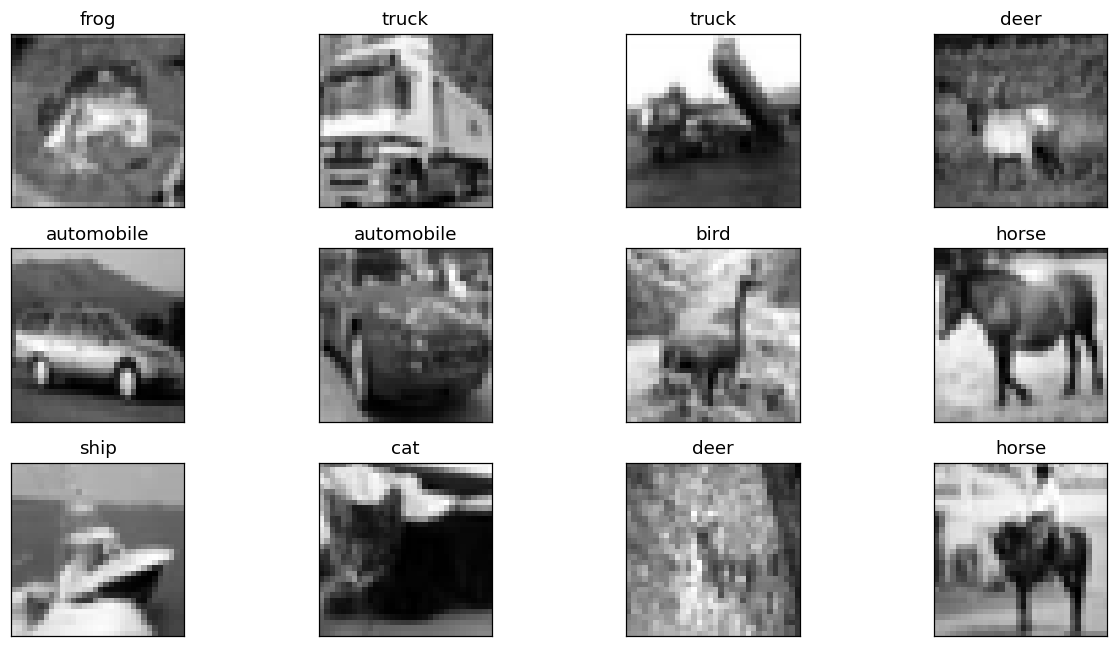

In [6]:
plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()


---
# 2. Construir la red neuronal

Construiremos la misma arquitectura conceptual vista en clase:

```text
Imagen 32×32
   ↓
Flatten
   ↓
1024 valores
   ↓
Dense(128)
   ↓
ReLU
   ↓
Dense(10)
   ↓
Logits
```

> La última capa **no** debe tener Softmax. Trabajaremos con logits.


In [7]:
# Mantengo la arquitectura del taller y dejo la salida como logits.
model = keras.Sequential([
    keras.Input(shape=(32, 32)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10)
])
model.summary()


Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 132,490 (517.54 KB)
 Trainable params: 132,490 (517.54 KB)
 Non-trainable params: 0 (0.00 B)


In [8]:
# Validación del ejercicio 2
expected_params = (1024 * 128 + 128) + (128 * 10 + 10)
assert model.count_params() == expected_params
print(f"✓ Arquitectura correcta: {model.count_params():,} parámetros")


✓ Arquitectura correcta: 132,490 parámetros


### Preguntas

**2.** ¿Por qué necesitamos `Flatten()` antes de la primera capa `Dense`?

**Respuesta:** Con Flatten convierto cada imagen en un vector, para que la capa Dense combine todos sus píxeles y produzca una clasificación por imagen. Sin aplanarla, Dense actuaría sobre la última dimensión y no haría la operación que pide esta arquitectura.



**3.** ¿Por qué la última capa tiene 10 neuronas?

**Respuesta:** Porque CIFAR-10 tiene 10 categorías. Cada salida representa la puntuación de una de ellas, en el mismo orden de class_names.



**4.** ¿Qué función cumple `ReLU`?

**Respuesta:** ReLU devuelve max(0, x): deja pasar los valores positivos y convierte los negativos en cero. Así la red puede aprender relaciones no lineales; sin una activación no lineal, varias capas densas seguirían siendo equivalentes a una transformación afín.




---
# 3. Configurar el entrenamiento

Usaremos:

- `Adam`
- `SparseCategoricalCrossentropy`
- `accuracy`

Como la red produce logits, la pérdida debe configurarse con `from_logits=True`.


In [9]:
lr_rate = 0.001
# Adam ajusta los pesos y accuracy cuenta la proporción de aciertos.
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_rate),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)


### Pregunta 5

¿Por qué usamos `from_logits=True`?

**Respuesta:** Porque la última capa entrega puntuaciones sin normalizar, llamadas logits. Con from_logits=True, la pérdida las procesa de forma numéricamente estable. Uso SparseCategoricalCrossentropy porque las etiquetas son enteros, no vectores one-hot.




---
# 4. Entrenar el modelo

Usaremos 10 épocas y mini-batches de 64 ejemplos. Completa `fit()`.


In [10]:
epochs = 10
batch_size = 64
# Entrenamos con las 50.000 imágenes que trae el conjunto de entrenamiento.
history = model.fit(
    X_train, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test, y_test),
    shuffle=True
)


Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.2479 - loss: 2.0638 - val_accuracy: 0.2930 - val_loss: 1.9762
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.3058 - loss: 1.9394 - val_accuracy: 0.3243 - val_loss: 1.9025
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3286 - loss: 1.8870 - val_accuracy: 0.3304 - val_loss: 1.8681
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.3439 - loss: 1.8498 - val_accuracy: 0.3445 - val_loss: 1.8396
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3550 - loss: 1.8222 - val_accuracy: 0.3501 - val_loss: 1.8226
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3612 - loss: 1.8030 - val_accuracy: 0.3568 - val_loss: 1.8069
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3688 - loss: 1.7869 - val_accuracy: 0.3587 - val_loss: 1.7985
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3745 - loss: 1.7725 - val_accuracy: 0.

### Preguntas

**6.** ¿Qué representa una `epoch`?

**Respuesta:** Es una pasada por las 50.000 imágenes de entrenamiento. En cada época se recorren todos los lotes y se ajustan los pesos.



**7.** ¿Qué representa `batch_size=64`?

**Respuesta:** Se usan lotes de hasta 64 imágenes para cada actualización. Hay 782 lotes por época: 781 de 64 y uno final de 16 imágenes.




## 4.1 Curvas de aprendizaje

Esta parte está resuelta.


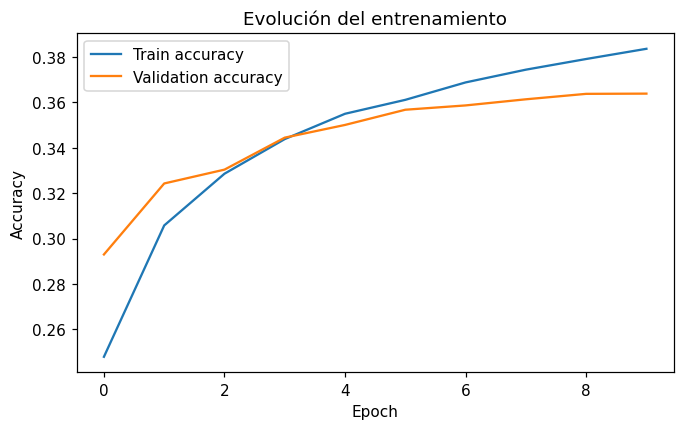

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolución del entrenamiento")
plt.legend()
plt.show()


### Pregunta 8

Observa las dos curvas. ¿Hay evidencia de overfitting? Justifica brevemente.

**Respuesta:** En esta ejecución no veo evidencia clara de sobreajuste. El accuracy de entrenamiento terminó en **38,37 %** y el de validación en **36,39 %**, una brecha de **1,98 puntos porcentuales**. Ambos mejoraron durante el entrenamiento y la pérdida de validación terminó en su mínimo. Esto tampoco significa que el desempeño sea alto: todavía hay muchas imágenes mal clasificadas.




In [12]:
from IPython.display import display, Markdown

# Miro los valores reales de las curvas antes de sacar una conclusión.
def comentar_curvas(history):
    h = history.history
    train = np.asarray(h["accuracy"])
    val = np.asarray(h["val_accuracy"])
    loss_val = np.asarray(h["val_loss"])
    ventana = min(5, len(train))
    aumento_train = train[-1] - train[-ventana]
    aumento_val = val[-1] - val[-ventana]
    brecha = train[-1] - val[-1]
    mejor = int(np.argmax(val)) + 1
    texto = (
        f"El accuracy de entrenamiento pasó de **{train[0]:.2%}** a **{train[-1]:.2%}**, "
        f"y el de validación de **{val[0]:.2%}** a **{val[-1]:.2%}**. "
        f"En las últimas {ventana} épocas, los cambios fueron "
        f"**{100*aumento_train:+.2f}** y **{100*aumento_val:+.2f} puntos porcentuales**, respectivamente. "
        f"La brecha final fue de **{100*brecha:.2f} puntos**, y el mejor accuracy de validación "
        f"se alcanzó en la época **{mejor}** ({val.max():.2%}). "
        f"La pérdida de validación terminó en **{loss_val[-1]:.4f}**, "
        f"frente a un mínimo de **{loss_val.min():.4f}**. "
    )
    if aumento_train > 0 and aumento_val <= 0 and brecha > 0:
        texto += "Veo señales de sobreajuste: al final mejora entrenamiento, pero validación no mejora."
    elif brecha > 0.05:
        texto += "La diferencia a favor de entrenamiento sugiere sobreajuste, aunque también reviso la evolución de las curvas y no solo el último valor."
    elif aumento_train > 0 and aumento_val > 0:
        texto += "Ambos conjuntos mejoran en el tramo final y no veo una separación grande al terminar. No tengo una señal clara de sobreajuste en este entrenamiento."
    else:
        texto += "Con estos valores no veo evidencia clara de sobreajuste. Las fluctuaciones por sí solas no son suficientes para afirmarlo."
    return texto

comentario_curvas = comentar_curvas(history)
display(Markdown(comentario_curvas))

El accuracy de entrenamiento pasó de **24.79%** a **38.37%**, y el de validación de **29.30%** a **36.39%**. En las últimas 5 épocas, los cambios fueron **+2.25** y **+0.71 puntos porcentuales**, respectivamente. La brecha final fue de **1.98 puntos**, y el mejor accuracy de validación se alcanzó en la época **10** (36.39%). La pérdida de validación terminó en **1.7809**, frente a un mínimo de **1.7809**. Ambos conjuntos mejoran en el tramo final y no veo una separación grande al terminar. No tengo una señal clara de sobreajuste en este entrenamiento.

---
# 5. Evaluar el modelo

Completa `evaluate()`.


In [13]:
# Ahora medimos el desempeño sin actualizar los pesos.
test_loss, test_accuracy = model.evaluate(
    X_test, y_test,
    batch_size=batch_size,
    verbose=0
)
print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")


Test loss     : 1.7809
Test accuracy : 0.3639
Accuracy (%)  : 36.39%


### Pregunta 9

Compara este resultado con Fashion-MNIST, utilizado en clase.

¿CIFAR-10 en escala de grises parece más fácil o más difícil para esta red? Justifica usando el accuracy obtenido.

**Respuesta:** CIFAR-10 en gris resultó más difícil para esta red: obtuve **36,39 % de accuracy**, frente a **87,95 %** en mi entrenamiento de Fashion-MNIST. La diferencia fue de **51,56 puntos porcentuales**. CIFAR-10 tiene fondos, posiciones y formas más variados; además, al pasarlo a gris se pierde información de color.

Para hacer la comparación revisé el notebook de clase **YourFirstDeepNN_FashionMNIST_Keras3.ipynb**. Allí se define una red FC con **Flatten → Dense(128, ReLU) → Dense(10)**, Adam con learning rate de **0,001**, **10 épocas** y **batch de 64**. Esa es la arquitectura y la configuración principal que usé en mi referencia de Fashion-MNIST. La entrada cambia según el dataset: 28×28 para Fashion-MNIST y 32×32 para CIFAR-10.

El archivo de clase quedó guardado con `MODEL_TYPE = "logistic"`, una salida parcial de la primera época y sin resultado en la celda de evaluación. Por eso no tomo ese dato parcial como accuracy final. Su tabla menciona un **87–89 % esperado** para la red FC, que es orientativo; mi **87,95 %** corresponde al entrenamiento adicional que dejo abajo, no a una medición guardada de la clase. La comparación es descriptiva, porque también cambian el tamaño y el contenido de los datasets.


In [14]:
# El archivo de clase no trae la evaluación final guardada.
# Por eso uso mi entrenamiento de referencia con su arquitectura FC.
# Si después tengo el accuracy final de la FC de clase, puedo ingresarlo entre 0 y 1.
accuracy_fashion_clase = None

if accuracy_fashion_clase is None:
    (xf_train, yf_train), (xf_test, yf_test) = keras.datasets.fashion_mnist.load_data()
    xf_train = xf_train.astype("float32") / 255.0
    xf_test = xf_test.astype("float32") / 255.0
    keras.utils.set_random_seed(SEED)
    model_fashion = keras.Sequential([
        keras.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(10),
    ])
    model_fashion.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    model_fashion.fit(xf_train, yf_train, epochs=10, batch_size=64, shuffle=True, verbose=2)
    _, accuracy_fashion = model_fashion.evaluate(xf_test, yf_test, verbose=0)
    origen_fashion = "mi entrenamiento adicional de referencia"
else:
    accuracy_fashion = float(accuracy_fashion_clase)
    assert 0 <= accuracy_fashion <= 1, "Escribe una proporción: por ejemplo, 0.85 equivale a 85%."
    origen_fashion = "el resultado que ingresé de la clase"

diferencia = 100 * (accuracy_fashion - test_accuracy)
if diferencia > 0:
    conclusion = "Para esta red, CIFAR-10 en gris resultó más difícil: obtuvo menos aciertos."
elif diferencia < 0:
    conclusion = "En esta comparación CIFAR-10 en gris obtuvo más aciertos; estos resultados no apoyan que fuera más difícil."
else:
    conclusion = "Los accuracies fueron iguales en esta comparación."
display(Markdown(
    f"Obtuve **{test_accuracy:.2%}** en CIFAR-10 en gris y **{accuracy_fashion:.2%}** "
    f"en Fashion-MNIST ({origen_fashion}). La diferencia Fashion − CIFAR fue de "
    f"**{diferencia:.2f} puntos porcentuales**. {conclusion} "
    "La comparación es descriptiva: los datasets tienen tamaños, resoluciones y contenidos distintos."
))

Epoch 1/10
938/938 - 3s - 4ms/step - accuracy: 0.8225 - loss: 0.5121
Epoch 2/10
938/938 - 4s - 4ms/step - accuracy: 0.8638 - loss: 0.3826
Epoch 3/10
938/938 - 3s - 3ms/step - accuracy: 0.8756 - loss: 0.3438
Epoch 4/10
938/938 - 3s - 3ms/step - accuracy: 0.8839 - loss: 0.3193
Epoch 5/10
938/938 - 2s - 3ms/step - accuracy: 0.8905 - loss: 0.3006
Epoch 6/10
938/938 - 2s - 3ms/step - accuracy: 0.8949 - loss: 0.2861
Epoch 7/10
938/938 - 3s - 3ms/step - accuracy: 0.8995 - loss: 0.2743
Epoch 8/10
938/938 - 3s - 3ms/step - accuracy: 0.9038 - loss: 0.2618
Epoch 9/10
938/938 - 3s - 3ms/step - accuracy: 0.9077 - loss: 0.2518
Epoch 10/10
938/938 - 3s - 3ms/step - accuracy: 0.9104 - loss: 0.2432


Obtuve **36.39%** en CIFAR-10 en gris y **87.95%** en Fashion-MNIST (mi entrenamiento adicional de referencia). La diferencia Fashion − CIFAR fue de **51.56 puntos porcentuales**. Para esta red, CIFAR-10 en gris resultó más difícil: obtuvo menos aciertos. La comparación es descriptiva: los datasets tienen tamaños, resoluciones y contenidos distintos.

---
# 6. Logits y Softmax

La salida de la red son 10 logits. Para interpretarlos como probabilidades necesitamos Softmax.


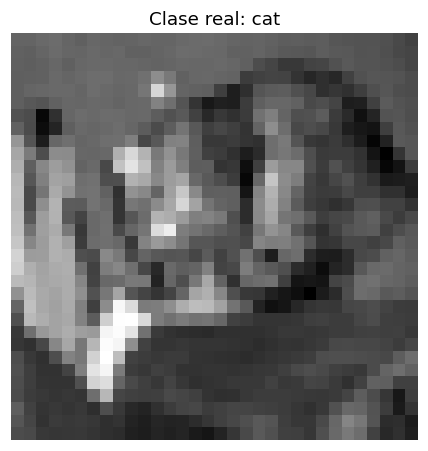

Logits:
[[ 1.0243716  -1.4633111   1.5322664   0.20417292  1.171925    0.1832146
   0.40249804  0.42288336 -0.23596188 -1.9235361 ]]


In [15]:
index = 0
image = X_test[index]
true_class = y_test[index]

plt.imshow(image, cmap="gray")
plt.title(f"Clase real: {class_names[true_class]}")
plt.axis("off")
plt.show()

image_batch = np.expand_dims(image, axis=0)
logits = model(image_batch, training=False)

print("Logits:")
print(keras.ops.convert_to_numpy(logits))


In [16]:
# Softmax convierte las puntuaciones en probabilidades.
probabilities = keras.ops.softmax(logits, axis=-1)
# Me quedo con la clase que tiene la probabilidad más alta.
prediction = keras.ops.argmax(probabilities, axis=1)
prediction = int(keras.ops.convert_to_numpy(prediction)[0])
assert np.allclose(keras.ops.convert_to_numpy(probabilities).sum(axis=1), 1.0)
print("Clase real     :", true_class)
print("Clase predicha :", prediction)
print("Nombre real    :", class_names[true_class])
print("Nombre predicho:", class_names[prediction])


Clase real     : 3
Clase predicha : 2
Nombre real    : cat
Nombre predicho: bird


In [17]:
probabilities_np = keras.ops.convert_to_numpy(probabilities)[0]

print("\nProbabilidades:")
for i, p in enumerate(probabilities_np):
    marker = " ← predicción" if i == prediction else ""
    print(f"{class_names[i]:12s}: {p:.4f}{marker}")

print("\nSuma:", probabilities_np.sum())



Probabilidades:
airplane    : 0.1614
automobile  : 0.0134
bird        : 0.2682 ← predicción
cat         : 0.0711
deer        : 0.1870
dog         : 0.0696
frog        : 0.0867
horse       : 0.0884
ship        : 0.0458
truck       : 0.0085

Suma: 0.99999994


### Pregunta 10

¿Por qué las probabilidades producidas por `Softmax` deben sumar aproximadamente 1?

**Respuesta:** Softmax calcula exp(z_i) dividido entre la suma de exp(z_j) de todas las clases. Al sumar esas fracciones obtengo 1. En el computador puede aparecer una diferencia muy pequeña por el redondeo de los números flotantes.




---
# 7. Varias predicciones

Esta parte está resuelta. Observa especialmente los errores del modelo.


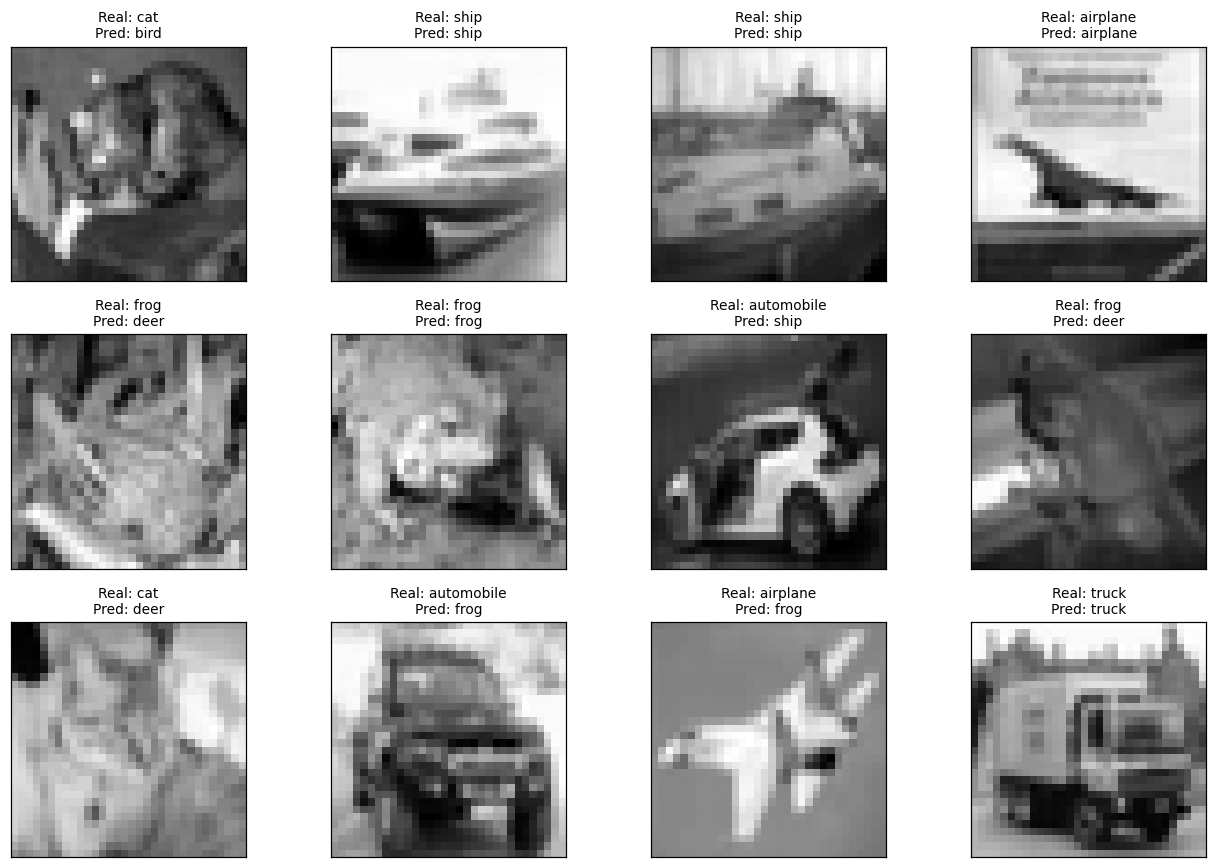

In [18]:
n = 12
logits_batch = model(X_test[:n], training=False)
predictions = keras.ops.argmax(logits_batch, axis=1)
predictions = keras.ops.convert_to_numpy(predictions)

plt.figure(figsize=(12, 8))
for i in range(n):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    real = class_names[y_test[i]]
    pred = class_names[predictions[i]]
    plt.title(f"Real: {real}\nPred: {pred}", fontsize=9)
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()


---
# 8. Reflexión final

### 1. ¿Cuál fue el accuracy final?

**Respuesta:** Obtuve **36,39 % de accuracy**, con **3639 aciertos de 10.000 imágenes** y una pérdida de **1,7809** en prueba.



### 2. ¿Qué clases parecen más difíciles de distinguir?

**Respuesta:** Las clases con menor recall fueron **cat (20,5 %), dog (28,1 %) y frog (30,6 %)**. El par con más confusiones fue **airplane y ship**, con **347 errores** entre las dos direcciones. Lo comprobé con todas las imágenes de prueba en la matriz de confusión de abajo; no me basé solamente en las doce predicciones de ejemplo.



### 3. Después de `Flatten()`, la imagen se convierte en un vector de 1024 valores. ¿Qué información importante sobre la imagen podría perderse al tratarla únicamente como un vector?

**Respuesta:** No se borran los valores de los píxeles y podría reconstruir la imagen si conozco su forma. Lo que deja de quedar explícito es la estructura bidimensional: qué píxeles son vecinos y cómo se organizan los patrones locales. La red densa no aprovecha esa estructura por diseño.



### 4. ¿Qué tipo de arquitectura podría aprovechar mejor la estructura espacial de las imágenes?

**Respuesta:** Una CNN, porque sus filtros recorren regiones de la imagen y aprenden patrones locales como bordes y texturas. Además, comparten pesos entre posiciones. Esto suele aprovechar mejor la estructura espacial, aunque el resultado debe comprobarse entrenando y evaluando el modelo.


---

## Para pensar

Nuestro modelo hace:

```text
32×32 → Flatten → 1024 valores → Dense → ReLU → Dense(10)
```

Sin embargo, una imagen tiene **estructura espacial**: existen bordes, formas y patrones locales.

Este resultado nos deja preparada la siguiente pregunta del curso:

> **¿Cómo puede una red aprovechar directamente la estructura espacial de una imagen?**

La respuesta será: **Convolutional Neural Networks (CNNs)**.


**Mi resultado final:** accuracy de **36.39%** (3639 aciertos de 10000), con pérdida **1.7809**.

Las clases con menor proporción de aciertos entre sus ejemplos reales fueron: **cat (20.50% de recall), dog (28.10% de recall), frog (30.60% de recall)**. El par más confundido fue **airplane / ship**, con **347 errores** sumando las dos direcciones. Esto me permite identificar las dificultades con los resultados, en lugar de asumirlas por el nombre de las clases.

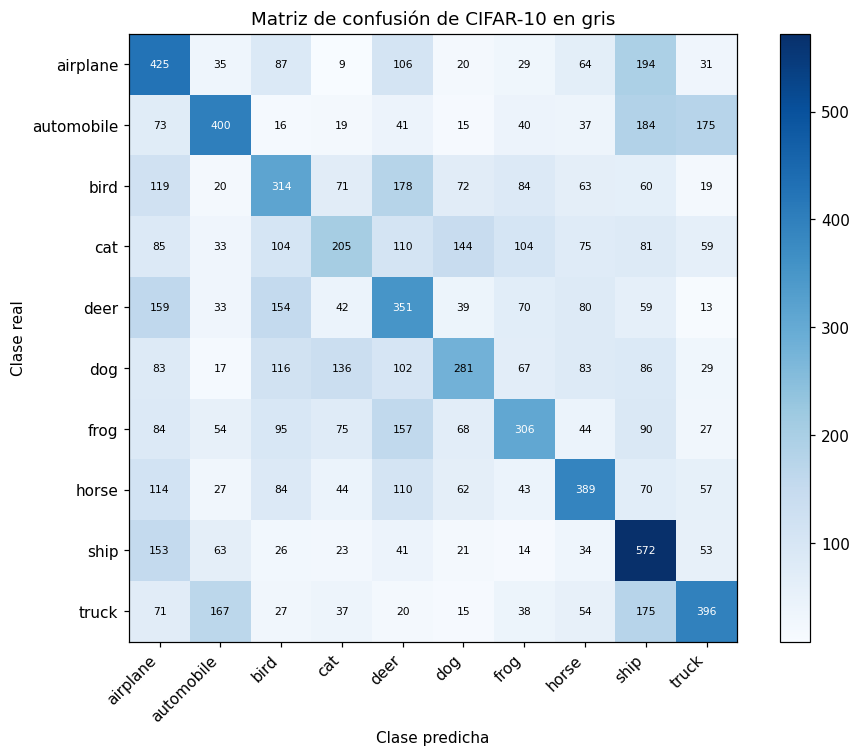

In [19]:
from sklearn.metrics import confusion_matrix

# Uso todas las imágenes de prueba para ver qué errores se repiten más.
all_logits = model.predict(X_test, batch_size=batch_size, verbose=0)
all_predictions = np.argmax(all_logits, axis=1)
cm = confusion_matrix(y_test, all_predictions, labels=np.arange(10))
aciertos = int(np.trace(cm))
assert np.isclose(test_accuracy, aciertos / len(y_test), atol=1e-6)
recall = np.diag(cm) / cm.sum(axis=1)
dificiles = np.argsort(recall)[:3]
confusiones = cm + cm.T
np.fill_diagonal(confusiones, 0)
a, b = np.unravel_index(np.argmax(confusiones), confusiones.shape)
clases_texto = ", ".join(f"{class_names[i]} ({recall[i]:.2%} de recall)" for i in dificiles)
display(Markdown(
    f"**Mi resultado final:** accuracy de **{test_accuracy:.2%}** "
    f"({aciertos} aciertos de {len(y_test)}), con pérdida **{test_loss:.4f}**.\n\n"
    f"Las clases con menor proporción de aciertos entre sus ejemplos reales fueron: **{clases_texto}**. "
    f"El par más confundido fue **{class_names[a]} / {class_names[b]}**, "
    f"con **{confusiones[a, b]} errores** sumando las dos direcciones. "
    "Esto me permite identificar las dificultades con los resultados, en lugar de asumirlas por el nombre de las clases."
))
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10), class_names, rotation=45, ha="right")
ax.set_yticks(range(10), class_names)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusión de CIFAR-10 en gris")
for i in range(10):
    for j in range(10):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max()/2 else "black")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

### Cierre

Completé la arquitectura, la configuración de la pérdida y el optimizador, el entrenamiento, la evaluación y las predicciones. Los comentarios y las conclusiones numéricas se calculan a partir de la ejecución para que coincidan con las gráficas. La semilla ayuda a repetir el experimento, aunque pueden aparecer diferencias entre equipos y versiones.

Referencia de las funciones: [documentación de Keras 3](https://keras.io/api/).